# Chronos-Bolt (fine-tuned) — FinX model (Owen)

**Target:** `target_next_ret` = next-day S&P 500 return
**Input:** `ret_index` only (the index's own past), like SARIMA and the as-is Chronos-Bolt.
**Validation:** the shared walk-forward harness (`walk_forward` in `src/finx_common.py`), same 3 folds as every FinX model.

| Fold | Fine-tuned on | Test |
|---|---|---|
| 1 | 2021-01-04 to 2023 | 2024 |
| 2 | 2021-01-04 to 2024 | 2025 |
| 3 | 2021-01-04 to 2025 | 2026 to 21 Sep |

**What the model is:** Chronos-Bolt is a pretrained time-series forecaster (Amazon, Nov 2024, T5 encoder-decoder). Amazon's model card says it
was trained on nearly 100 billion time-series observations from general public collections; it was not trained
specifically on stock returns. It cuts the history into 16-day patches, scales it by its own mean absolute value, and
outputs 9 quantiles (10% to 90%) of the next value in one pass, without sampling, so the same input always gives the
same forecast.

**What changes vs the as-is run:** only a short fine-tune per fold. Same checkpoint (`amazon/chronos-bolt-small`,
48M parameters), same input, same prediction code (`chronos_model.predict` is reused), so any difference in the
scores comes from fine-tuning alone.

**Fine-tuning settings (fixed in advance, no tuning on test years):**
- Examples: every training day e with at least 128 earlier days is one example: history `ret_index[:e]` → next value `ret_index[e]`.
- Validation slice: examples whose target falls in the last 10% of the training period (`val_split`). The rest are trained on.
- Loss: the model's own quantile loss. AdamW, learning rate 1e-5, batch 32, at most 1,000 steps, seed 42.
- Early stopping: validation loss checked every 25 steps; stop after 8 checks without improvement; keep the best
  weights. Step 0 (the as-is model) counts as a candidate, so fine-tuning is only kept if it lowers validation loss.
- Training runs on the GPU (GTX 1650 here). The fine-tuned model is then moved to the CPU, so prediction latency is
  comparable with every other model. Training on a GPU can differ very slightly between runs.

"Train time" is real training time here (fine-tune + load), unlike the as-is run where it is only load time.
Code: `models/chronos_ft_model.py`.

**Limitation:** Chronos-Bolt was released in Nov 2024, so its pretraining data could overlap the start of the 2024 test
year. It was not trained specifically on stock returns, so the risk is small, but it is a possible look-ahead.

**Outputs:** `outputs/preds_chronos_ft.csv` and `outputs/timing_chronos_ft.json` (written by the harness);
`outputs/chronos_ft/` holds the training log, tables and figures.

## 1. Setup
Needs `pip install chronos-forecasting` (brings PyTorch). The weights (about 190 MB) download once on first use. Fine-tuning uses the GPU if PyTorch can see one (a CUDA build of PyTorch); otherwise it runs on the CPU, much slower.

In [1]:
import json
import math
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("USE_TF", "0")       # stop transformers importing TensorFlow if it is installed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "src"), str(ROOT / "models")]
import config as C
import chronos_ft_model as M # fit / predict / predict_quantiles / NAME
from finx_common import FOLDS, fold_split, load_master, score, walk_forward

warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 160)
OUT = C.OUT_DIR / "chronos_ft"
OUT.mkdir(parents=True, exist_ok=True)
import torch
print(f"PyTorch {torch.__version__}; GPU for fine-tuning: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU)'}")

PyTorch 2.7.1+cu118; GPU for fine-tuning: NVIDIA GeForce GTX 1650


## 2. Load the frozen master

In [2]:
master = load_master()                 # checksum and row count are checked on load
ret = master["ret_index"]
print(f"{len(master)} trading days: {master.index.min().date()} to {master.index.max().date()}")
assert (master[C.TARGET].iloc[:-1].values == ret.shift(-1).iloc[:-1].values).all()
assert len(master) <= M.CONTEXT
print(f"Check passed: target on day t = ret_index on day t+1, so the forecast for day t+1 uses ret_index up to day t. "
      f"Longest history ({len(master)} days) fits in Bolt's {M.CONTEXT}-value context.")

1435 trading days: 2021-01-04 to 2026-09-21
Check passed: target on day t = ret_index on day t+1, so the forecast for day t+1 uses ret_index up to day t. Longest history (1435 days) fits in Bolt's 2048-value context.


## 3. Walk-forward run (shared harness)
`walk_forward` fine-tunes once per fold on that fold's training years only, predicts every test day, times the
fine-tune (train time) and the latency of one next-day prediction, and writes `preds_chronos_ft.csv` and
`timing_chronos_ft.json`. The warm-up line makes sure the weights are downloaded before the timed run. The wrapper keeps
each fold's model so the next sections can read its training log and quantiles. Takes a few minutes on a GTX 1650.

In [3]:
import chronos_model as base
base.fit(master.iloc[:5])               # warm-up: download / cache the weights (not timed)

fitted = []

def fit_and_keep(train):
    m = M.fit(train)
    fitted.append(m)
    return m

P, timing = walk_forward(fit_and_keep, M.predict, M.NAME, df=master)

Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


[chronos_ft] fold 2024: train 753 days, test 252 days, train 54.3s, 52.742 ms for one prediction


[chronos_ft] fold 2025: train 1005 days, test 250 days, train 51.6s, 54.317 ms for one prediction


[chronos_ft] fold 2026: train 1255 days, test 180 days, train 94.3s, 85.178 ms for one prediction


In [4]:
# Checks that the run matches the spec
n_test = sum(len(fold_split(master, f)[1]) for f in FOLDS)
assert len(fitted) == 3
assert len(P) == n_test, (len(P), n_test)
assert P["pred"].notna().all()
assert all(str(m.model.device) == M.DEVICE for m in fitted)
# Fine-tuning used only training days: examples = training days after the first MIN_CONTEXT
for f, m in zip(FOLDS, fitted):
    n_train = len(fold_split(master, f)[0])
    assert m.ft_info["fit_examples"] + m.ft_info["val_examples"] == n_train - M.MIN_CONTEXT

# No peeking: a forecast made with data only up to day t equals the one from the full run
d = P.index[300]
alone = M.predict(fitted[1], master.loc[:d], pd.DatetimeIndex([d])).iloc[0]
assert np.isclose(alone, P.loc[d, "pred"], atol=1e-6), (alone, P.loc[d, "pred"])
print(f"{len(P)} pooled predictions over {len(fitted)} folds; forecast for {d.date()} is the same with or without later data.")

682 pooled predictions over 3 folds; forecast for 2025-03-14 is the same with or without later data.


## 4. Fine-tuning per fold
"Best step" is the step whose weights were kept (0 = the as-is model was kept). "Val loss change" compares the kept
weights with the as-is model on the validation slice (negative = fine-tuning helped there). The chart shows validation
loss during training, relative to the as-is model; a rising line after the best step is overfitting, which early stopping cuts off.

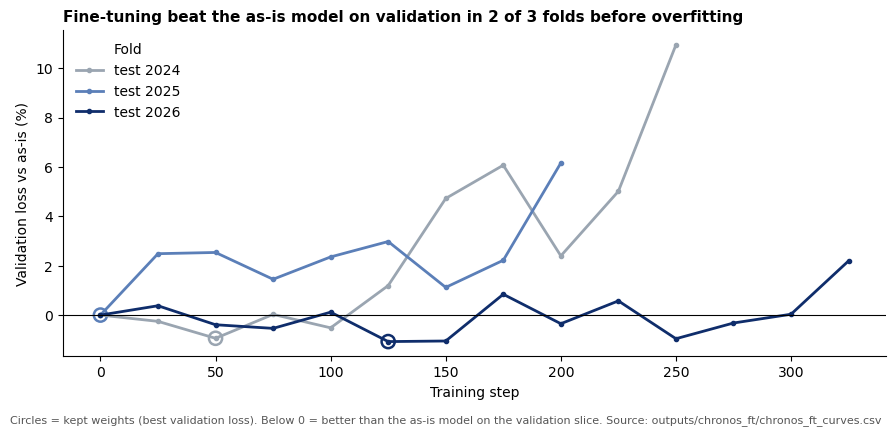

,test_year,train_days,fit_examples,val_examples,steps_run,best_step,val_loss_as_is,val_loss_kept,val loss change (%),train_s,device
0,2024,753,549,76,250,50,0.42614,0.42213,-0.94,54.3,cuda
1,2025,1005,776,101,200,0,0.46013,0.46013,0.00,51.6,cuda
2,2026,1255,1001,126,325,125,0.37627,0.37223,-1.07,94.3,cuda


In [5]:
rows, curves = [], []
for f, m in zip(FOLDS, fitted):
    i = m.ft_info
    rows.append({"test_year": f[0], "train_days": len(fold_split(master, f)[0]), "fit_examples": i["fit_examples"],
                 "val_examples": i["val_examples"], "steps_run": i["steps_run"], "best_step": i["best_step"],
                 "val_loss_as_is": round(i["val_loss_as_is"], 5), "val_loss_kept": round(i["val_loss_best"], 5),
                 "val loss change (%)": round(100 * (i["val_loss_best"] / i["val_loss_as_is"] - 1), 2),
                 "train_s": round(timing["train_s"][f[0]], 1), "device": i["device"]})
    curves.append(i["log"].assign(test_year=f[0]))
training = pd.DataFrame(rows)
training.to_csv(OUT / "chronos_ft_training.csv", index=False)
pd.concat(curves).to_csv(OUT / "chronos_ft_curves.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.2))
for (f, m), col in zip(zip(FOLDS, fitted), ["#9aa5b1", "#5b7fb8", "#0f2d6b"]):
    lg = m.ft_info["log"]
    rel = 100 * (lg["val_loss"] / m.ft_info["val_loss_as_is"] - 1)
    ax.plot(lg["step"], rel, color=col, lw=2, marker="o", ms=3, label=f"test {f[0]}")
    ax.scatter([m.ft_info["best_step"]], [100 * (m.ft_info["val_loss_best"] / m.ft_info["val_loss_as_is"] - 1)],
               s=90, facecolors="none", edgecolors=col, lw=1.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Training step")
ax.set_ylabel("Validation loss vs as-is (%)")
n_kept = int((training["best_step"] > 0).sum())
ax.set_title(f"Fine-tuning beat the as-is model on validation in {n_kept} of {len(FOLDS)} folds before overfitting"
             if n_kept else "Fine-tuning never beat the as-is model on validation", fontsize=11, fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, title="Fold", loc="upper left")
fig.text(0.01, -0.02, "Circles = kept weights (best validation loss). Below 0 = better than the as-is model on the validation slice. "
         "Source: outputs/chronos_ft/chronos_ft_curves.csv", fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(OUT / "fig_chronos_ft_val_loss.png", dpi=200, bbox_inches="tight")
plt.show()
training

## 5. Forecast band per fold
Fine-tuned Chronos-Bolt gives a range, not just one number. Below, the 10% and 90% quantiles form an 80% band around the median.
If the band were well calibrated, about 80% of actual returns would fall inside it. "Band vs VIX" is the correlation
between the band's width and that day's VIX: a positive value means the model widens its range on stressed days, even
though it never sees VIX.

In [6]:
Q = pd.concat([M.predict_quantiles(m, master, fold_split(master, f)[1].index) for f, m in zip(FOLDS, fitted)])
Q = Q.join(P[["fold", "actual", "VIX"]])
assert np.allclose(Q["q50"], P["pred"])
Q.to_csv(OUT / "chronos_ft_quantiles.csv")

rows = []
for fold, m in zip(FOLDS, fitted):
    train, test = fold_split(master, fold)
    q = Q[Q["fold"].astype(str) == fold[0]]
    width = q["q90"] - q["q10"]
    rows.append({"test_year": fold[0], "train_days": len(train), "test_days": len(test),
                 "median forecast min (%)": round(q["q50"].min() * 100, 4),
                 "median forecast max (%)": round(q["q50"].max() * 100, 4),
                 "inside 10-90% band (%)": round(100 * ((q["actual"] >= q["q10"]) & (q["actual"] <= q["q90"])).mean(), 1),
                 "band width mean (%)": round(width.mean() * 100, 3),
                 "band vs VIX (corr)": round(width.corr(q["VIX"]), 3)})
folds = pd.DataFrame(rows)
folds.to_csv(OUT / "chronos_ft_folds.csv", index=False)
folds

,test_year,train_days,test_days,median forecast min (%),median forecast max (%),inside 10-90% band (%),band width mean (%),band vs VIX (corr)
0,2024,753,252,-0.0494,0.2498,80.6,1.973,0.749
1,2025,1005,250,-0.2847,0.3108,77.2,2.032,0.764
2,2026,1255,180,-0.0275,0.2038,71.7,1.640,0.580


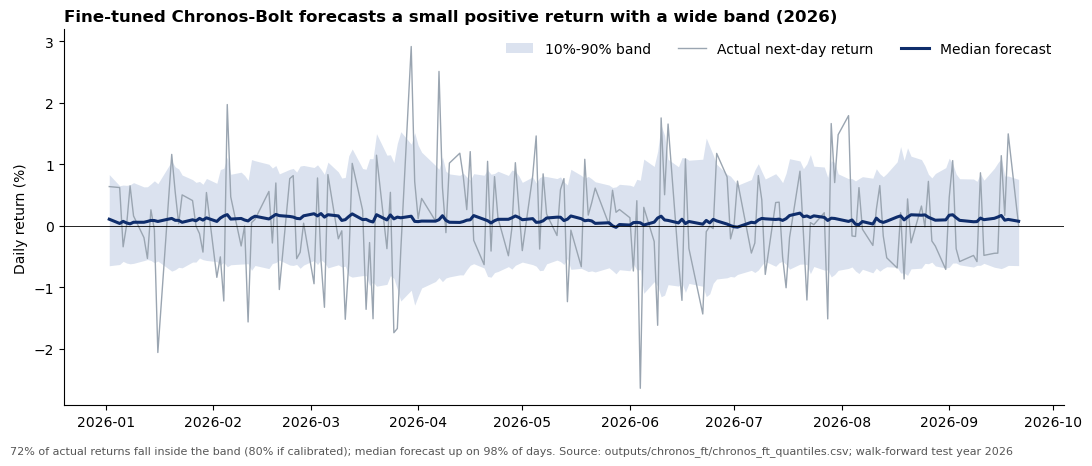

In [7]:
yr = FOLDS[-1][0]
q = Q[Q["fold"].astype(str) == yr]
inside = 100 * ((q["actual"] >= q["q10"]) & (q["actual"] <= q["q90"])).mean()
up = 100 * (q["q50"] > 0).mean()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(q.index, q["q10"] * 100, q["q90"] * 100, color="#5b7fb8", alpha=0.22, lw=0, label="10%-90% band")
ax.plot(q.index, q["actual"] * 100, color="#9aa5b1", lw=1, label="Actual next-day return")
ax.plot(q.index, q["q50"] * 100, color="#0f2d6b", lw=2.2, label="Median forecast")
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Daily return (%)")
ax.set_title(f"Fine-tuned Chronos-Bolt forecasts a small {'positive' if up >= 50 else 'negative'} return with a wide band ({yr})",
             fontsize=12, fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=3)
fig.text(0.01, -0.02, f"{inside:.0f}% of actual returns fall inside the band (80% if calibrated); median forecast up on {up:.0f}% of days. "
         f"Source: outputs/chronos_ft/chronos_ft_quantiles.csv; walk-forward test year {yr}", fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(OUT / f"fig_chronos_ft_band_{yr}.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Scores
All test days pooled (not averaged per fold), then each fold. Naive = always predict 0, so naive RMSE = sqrt(mean(actual^2)).
Skill vs naive = 1 − RMSE(model) ÷ RMSE(naive). "Always up (%)" is the share of days the market rose, the direction
benchmark. "Forecast up (%)" is the share of days the model predicted a positive return: at 100%, its Direction equals
"always up" by construction.

In [8]:
def row(g, label):
    a = g["actual"]
    s = score(a, g["pred"], float(np.sqrt((a ** 2).mean())))
    up = 100 * (a[a != 0] > 0).mean()
    return {"test days": label, "n": len(g), "RMSE (%)": s["RMSE"] * 100, "MAE (%)": s["MAE"] * 100,
            "Direction (%)": s["Direction %"], "Always up (%)": up,
            "Skill vs naive (%)": s["Skill vs naive"] * 100, "Forecast up (%)": 100 * (g["pred"] > 0).mean()}

scores = pd.DataFrame([row(P, "pooled")] + [row(g, str(f)) for f, g in P.groupby("fold")]).round(3)
scores.to_csv(OUT / "chronos_ft_scores.csv", index=False)
t = {k: float(np.mean(list(v.values()))) for k, v in timing.items() if k != "hardware"}
print(f"Train (fine-tune) time per fold: {t['train_s']:.2f} s   Inference per day: {t['latency_ms_per_day']:.2f} ms   "
      f"Hardware: {timing['hardware']}")
scores

Train (fine-tune) time per fold: 66.73 s   Inference per day: 64.08 ms   Hardware: {'cpu': 'AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD', 'cores': 16, 'gpu': 'NVIDIA GeForce GTX 1650'}


,test days,n,RMSE (%),MAE (%),Direction (%),Always up (%),Skill vs naive (%),Forecast up (%)
0,pooled,682,0.968,0.657,54.839,56.012,-0.229,97.067
1,2024,252,0.802,0.592,56.349,56.746,-0.314,99.603
2,2025,250,1.186,0.733,56.800,58.000,-0.468,94.000
3,2026,180,0.835,0.644,50.000,52.222,0.539,97.778


## 7. Fine-tuned vs as-is (same model, same input)
Both runs use `chronos-bolt-small` and the same prediction code; the only difference is the fine-tune. The
**Diebold-Mariano test** compares them day by day: d = squared error as-is − squared error fine-tuned. A positive z
means fine-tuning helped; p < 0.05 means the difference is unlikely to be chance (one-step forecasts, normal approximation).
Needs `outputs/preds_chronos_asis.csv` (run `notebooks/model_chronos.ipynb` first).

In [9]:
A = pd.read_csv(C.OUT_DIR / "preds_chronos_asis.csv", index_col=0, parse_dates=True)
assert (A.index == P.index).all() and np.allclose(A["actual"], P["actual"])
QA = pd.read_csv(C.OUT_DIR / "chronos" / "chronos_quantiles.csv", index_col=0, parse_dates=True)

def band(q):
    return 100 * ((q["actual"] >= q["q10"]) & (q["actual"] <= q["q90"])).mean()

rows = []
for lab, g, q in (("as-is", A, QA), ("fine-tuned", P, Q)):
    for part, gg in [("pooled", g)] + [(str(f), x) for f, x in g.groupby("fold")]:
        r = row(gg, part)
        qq = q.loc[gg.index]
        rows.append({"run": lab, "test days": part, "RMSE (%)": r["RMSE (%)"], "Skill vs naive (%)": r["Skill vs naive (%)"],
                     "Direction (%)": r["Direction (%)"], "Forecast up (%)": r["Forecast up (%)"], "inside band (%)": band(qq)})
vs = pd.DataFrame(rows).set_index(["run", "test days"]).round(3)
vs.to_csv(OUT / "chronos_ft_vs_asis.csv")

d = (A["actual"] - A["pred"]) ** 2 - (P["actual"] - P["pred"]) ** 2
dm_z = d.mean() / math.sqrt(d.var(ddof=1) / len(d))
dm_p = math.erfc(abs(dm_z) / math.sqrt(2))
closer = 100 * ((P["actual"] - P["pred"]).abs() < (A["actual"] - A["pred"]).abs()).mean()
print(f"Diebold-Mariano (as-is vs fine-tuned): z = {dm_z:+.2f}, p = {dm_p:.3f}; "
      f"fine-tuned is closer to the actual return on {closer:.1f}% of days.")
vs

Diebold-Mariano (as-is vs fine-tuned): z = -0.39, p = 0.700; fine-tuned is closer to the actual return on 49.0% of days.


RMSE (%)  Skill vs naive (%)  Direction (%)  Forecast up (%)  inside band (%)
run        test days                                                                               
as-is      pooled        0.968              -0.151         55.865           96.041           73.900
           2024          0.798               0.129         56.746           96.032           71.825
           2025          1.186              -0.468         56.800           94.000           77.200
           2026          0.837               0.368         53.333           98.889           72.222
fine-tuned pooled        0.968              -0.229         54.839           97.067           76.979
           2024          0.802              -0.314         56.349           99.603           80.556
           2025          1.186              -0.468         56.800           94.000           77.200
           2026          0.835               0.539         50.000           97.778           71.667

## 8. Chronos-Bolt (fine-tuned) next to the models already run
Same pooled scoring, read from each model's `outputs/preds_<name>.csv`. Timings come from each model's own
`timing_<name>.json`, so they are only comparable when the hardware column matches.

In [10]:
LABELS = {"naive": "Naive (return = 0)", "arima": "ARIMA", "sarima": "SARIMA", "xgboost": "XGBoost",
          "dnn": "DNN", "lstm": "LSTM", "chronos_asis": "Chronos-Bolt (as-is)", "chronos_ft": "Chronos-Bolt (fine-tuned)"}
rows = []
for k, lab in LABELS.items():
    f = C.OUT_DIR / f"preds_{k}.csv"
    if not f.exists():
        continue
    g = pd.read_csv(f, index_col=0, parse_dates=True)
    tj = json.loads((C.OUT_DIR / f"timing_{k}.json").read_text())
    r = row(g, lab)
    r.update({"Train / load per fold (s)": np.mean(list(tj["train_s"].values())),
              "Inference per day (ms)": np.mean(list(tj["latency_ms_per_day"].values())),
              "Hardware": f"{tj['hardware']['cpu']}, {tj['hardware']['cores']} cores, GPU {tj['hardware']['gpu']}"})
    rows.append(r)
compare = pd.DataFrame(rows).rename(columns={"test days": "model"}).drop(columns=["n", "Always up (%)"]).round(3)
compare.loc[compare["model"] == LABELS["naive"], ["Direction (%)", "Forecast up (%)"]] = np.nan   # 0 has no direction
compare.to_csv(OUT / "chronos_ft_vs_models.csv", index=False)
compare

,model,RMSE (%),MAE (%),Direction (%),Skill vs naive (%),Forecast up (%),Train / load per fold (s),Inference per day (ms),Hardware
0,Naive (return = 0),0.966,0.658,NaN,0.000,NaN,0.000,0.042,"arm, 11 cores, GPU none"
1,ARIMA,0.964,0.655,54.106,0.228,96.041,1.463,2.533,"arm, 11 cores, GPU none"
2,SARIMA,0.964,0.654,56.012,0.260,100.000,10.864,5.538,"arm, 12 cores, GPU none"
3,XGBoost,0.962,0.655,54.985,0.387,94.868,0.092,12.840,"arm, 11 cores, GPU none"
4,DNN,1.024,0.731,52.346,-5.959,57.331,7.148,33.277,"AMD64 Family 23 Model 96 Stepping 1, Authentic..."
5,Chronos-Bolt (as-is),0.968,0.656,55.865,-0.151,96.041,1.567,53.376,"AMD64 Family 25 Model 68 Stepping 1, Authentic..."
6,Chronos-Bolt (fine-tuned),0.968,0.657,54.839,-0.229,97.067,66.728,64.079,"AMD64 Family 25 Model 68 Stepping 1, Authentic..."


## 9. Notes for the group chat
Three lines, each quoting a number from the tables above. The cell below fills the numbers from the computed results;
the verdict words (better/worse, above/below) are also computed. Replace each `[reason: ...]` with a short explanation
only after looking at the outputs. Do not tune on the test years to change these numbers.

In [11]:
s = scores.iloc[0]
f = scores.iloc[1:].set_index("test days")
c = compare.set_index("model")
better = lambda x: "better" if x > 0 else "worse"
best_fold, worst_fold = f["Skill vs naive (%)"].idxmax(), f["Skill vs naive (%)"].idxmin()
others = c.drop(index=["Chronos-Bolt (as-is)", "Chronos-Bolt (fine-tuned)", "Naive (return = 0)"], errors="ignore")
best_other = others["Skill vs naive (%)"].idxmax()
twin = "Chronos-Bolt (as-is)"
vs_twin = (f"; {twin} scores {c.loc[twin, 'Skill vs naive (%)']:+.2f}%" if twin in c.index else "")
print(f"1. RMSE: Fine-tuned Chronos-Bolt {s['RMSE (%)']:.3f}% vs naive {100 * np.sqrt((P['actual'] ** 2).mean()):.3f}% "
      f"(skill {s['Skill vs naive (%)']:+.2f}%), so {better(s['Skill vs naive (%)'])} than naive on all {int(s['n'])} days; "
      f"best non-Chronos model is {best_other} at {others.loc[best_other, 'Skill vs naive (%)']:+.2f}%{vs_twin}. [reason: ...]")
print(f"2. Direction: {s['Direction (%)']:.1f}% vs always-up {s['Always up (%)']:.1f}%, "
      f"{'above' if s['Direction (%)'] > s['Always up (%)'] else 'not above'} the benchmark; "
      f"forecast up on {s['Forecast up (%)']:.1f}% of days. [reason: ...]")
print(f"3. Fine-tuned vs as-is: skill {vs.loc[('as-is', 'pooled'), 'Skill vs naive (%)']:+.2f}% -> {s['Skill vs naive (%)']:+.2f}%, "
      f"Diebold-Mariano p = {dm_p:.3f}; kept weights from steps {', '.join(str(x) for x in training['best_step'])} "
      f"(0 = as-is kept). [reason: ...]")

1. RMSE: Fine-tuned Chronos-Bolt 0.968% vs naive 0.966% (skill -0.23%), so worse than naive on all 682 days; best non-Chronos model is XGBoost at +0.39%; Chronos-Bolt (as-is) scores -0.15%. [reason: ...]
2. Direction: 54.8% vs always-up 56.0%, not above the benchmark; forecast up on 97.1% of days. [reason: ...]
3. Fine-tuned vs as-is: skill -0.15% -> -0.23%, Diebold-Mariano p = 0.700; kept weights from steps 50, 0, 125 (0 = as-is kept). [reason: ...]


In [12]:
s = scores.iloc[0]
print(f"Chronos-Bolt (fine-tuned) (all {int(s['n'])} test days): RMSE {s['RMSE (%)']:.3f}%  MAE {s['MAE (%)']:.3f}%  "
      f"Direction {s['Direction (%)']:.1f}%  Skill vs naive {s['Skill vs naive (%)']:+.2f}%")
print(f"Train (fine-tune) {t['train_s']:.2f} s per fold  |  Inference {t['latency_ms_per_day']:.2f} ms per day  |  "
      f"Hardware: {timing['hardware']['cpu']}, {timing['hardware']['cores']} cores, GPU {timing['hardware']['gpu']} (predictions on {M.DEVICE})")

Chronos-Bolt (fine-tuned) (all 682 test days): RMSE 0.968%  MAE 0.657%  Direction 54.8%  Skill vs naive -0.23%
Train (fine-tune) 66.73 s per fold  |  Inference 64.08 ms per day  |  Hardware: AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD, 16 cores, GPU NVIDIA GeForce GTX 1650 (predictions on cpu)
